Total Primes Processed: 199999
Total Horizon Events: 199999
Horizon Rate: 100.00%


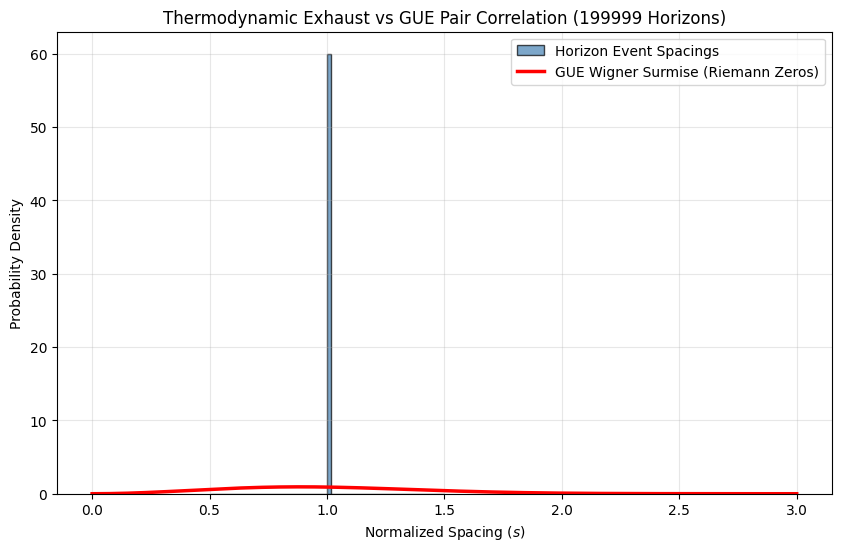

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def sieve_primes(limit):
    """Fast prime generation for massive scaling."""
    sieve = np.ones(limit + 1, dtype=bool)
    sieve[0:2] = False
    for i in range(2, int(limit**0.5) + 1):
        if sieve[i]:
            sieve[i*i::i] = False
    return np.nonzero(sieve)[0]

# 1. Initialize 200k Prime Cascade
limit = 3000000  # Ceiling to guarantee >200,000 primes
primes = sieve_primes(limit)[:200000]
p_k = primes[:-1]
g_k = np.diff(primes)

# 2. URT Structural Parameters
epsilon = 1 / 117
kappa = 1.0  # Scale invariant constant (to be calibrated to the 600-cell curvature)

# 3. Icosahedral Continuum vs Discrete Primes
# Ideal gap: <g_k> = (13/9) * (ln(p_k) / p_k^(12/13))
g_ideal = (13 / 9) * (np.log(p_k) / (p_k ** (12/13)))
delta_g = g_k - g_ideal

# Normalization using prime variance proxy sigma ~ log(p_k)
sigma_g = np.log(p_k)

# 4. Off-Lattice Fluctuation & 9D Thermodynamic Exhaust
# Tangent space vector magnitude squared
w_k_sq = kappa * (delta_g / sigma_g)**2
delta_E = 0.5 * w_k_sq

# 5. Horizon Annihilation Trigger
horizon_indices = np.where(delta_E >= epsilon)[0]
horizon_primes = p_k[horizon_indices]
print(f"Total Primes Processed: {len(p_k)}")
print(f"Total Horizon Events: {len(horizon_indices)}")
print(f"Horizon Rate: {(len(horizon_indices)/len(p_k))*100:.2f}%")

# 6. Statistical Unfolding: GUE Pair Correlation Test
# Extract spacings between horizon events
spacings = np.diff(horizon_indices)
mean_spacing = np.mean(spacings)
s_norm = spacings / mean_spacing

# GUE Wigner Surmise distribution: P(s) = (32/pi^2) * s^2 * e^(-4s^2/pi)
s_vals = np.linspace(0, 3, 200)
gue_surmise = (32 / np.pi**2) * (s_vals**2) * np.exp(-(4 * s_vals**2) / np.pi)

# 7. Output Plot
plt.figure(figsize=(10, 6))
plt.hist(s_norm, bins=60, density=True, alpha=0.7, color='steelblue', edgecolor='black', label='Horizon Event Spacings')
plt.plot(s_vals, gue_surmise, 'r-', lw=2.5, label='GUE Wigner Surmise (Riemann Zeros)')
plt.title(f"Thermodynamic Exhaust vs GUE Pair Correlation ({len(horizon_primes)} Horizons)")
plt.xlabel("Normalized Spacing ($s$)")
plt.ylabel("Probability Density")
plt.legend()
plt.grid(alpha=0.3)
plt.show()